# Appendix simulation fidelity
Redraw the five appendix comparisons from saved samples and metrics using the `lightning` kernel. Plotting code is contained in this notebook.

In [3]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scdeepsim").is_dir())
RESULTS_ROOT = PROJECT_ROOT / "experiments/outputs/simulation_fidelity/unified-20260915-formal/nodes"
OUTPUT_DIR = PROJECT_ROOT / "paper/figures/results"

# Default paths for reproducing simulation fidelity results
# RESULTS_ROOT = PROJECT_ROOT / "experiments/outputs/reproduction"
# OUTPUT_DIR = RESULTS_ROOT / "appendix_figures"

CASES = [
    ("pancreas", "learned_distribution"),
    ("immune", "learned_distribution"),
    ("lung", "reconstruction"),
    ("pancreas", "reconstruction"),
    ("immune", "reconstruction"),
]

COLORS = {
    "real": "#4c566a",
    "scdeepsim": "#0072b2",
    "scdiffusion": "#cc79a7",
    "scvi_prior": "#009e73",
    "scdesign3": "#d55e00",
    "vae_reconstruction": "#6a3d9a",
    "scvi_posterior": "#56b4e9",
    "zinbwave": "#e69f00",
}
FIGSIZE = (15, 8.8)
UMAP_POINT_SIZE, UMAP_ALPHA = 5, 0.65
GENE_POINT_SIZE, GENE_ALPHA = 8, 0.4


## Saved results and joint UMAPs
Compute each projection once using the recorded method order, subsampling, seed, and UMAP settings. The statistics and coordinates remain in memory for plotting edits.

In [4]:
results = {}
for dataset, category in CASES:
    print(f"Preparing {dataset}: {category}", flush=True)
    run_name = f"fidelity_{dataset}" if category == "learned_distribution" else f"fidelity_{dataset}_posterior"

    # Change the folder path if your results are stored elsewhere. The default locations following the README instructions are:
    # folder = RESULTS_ROOT / run_name / "results"
    # metadata_path = folder / "baseline_metadata.json"
    # metrics_path = folder / "metrics.csv"
    # samples_path = folder / "samples.npz"
    folder = RESULTS_ROOT / dataset / "aggregate/official"
    metadata_path = folder / f"{category}_baseline_metadata.json"
    metrics_path = folder / f"{category}_metrics.csv"
    samples_path = folder / "_aggregate_work/merged_samples.npz"
    
    

    config = json.loads(metadata_path.read_text())["config"]
    metrics = pd.read_csv(metrics_path)
    methods = config["methods"]
    keys = ["real", *methods]
    names = metrics.set_index("method_key")["method"].to_dict()
    with np.load(samples_path) as archive:
        samples = {key: archive[key] for key in keys}

    means = {key: x.mean(axis=0) for key, x in samples.items()}
    variances = {key: x.var(axis=0) for key, x in samples.items()}
    seed = config["seed"]
    max_cells = config["eval"]["umap_max_cells_per_method"]
    subsets = []
    for offset, key in enumerate(keys):
        x = samples[key]
        if max_cells is not None and len(x) > max_cells:
            indices = np.random.default_rng(seed + offset).choice(len(x), max_cells, replace=False)
            x = x[indices]
        subsets.append(x)

    embedding = umap.UMAP(
        n_neighbors=config["eval"]["umap_n_neighbors"],
        min_dist=config["eval"]["umap_min_dist"],
        metric="euclidean",
        random_state=seed,
        n_components=2,
    ).fit_transform(np.vstack(subsets))
    embeddings = dict(zip(keys, np.split(embedding, np.cumsum([len(x) for x in subsets])[:-1])))
    results[(dataset, category)] = {
        "methods": methods, "keys": keys, "names": names, "metrics": metrics,
        "means": means, "variances": variances, "embeddings": embeddings,
        "dpi": config["figure"]["dpi"],
    }
    del samples, subsets, x


Preparing pancreas: learned_distribution


/opt/miniconda3/envs/lightning/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Preparing immune: learned_distribution


/opt/miniconda3/envs/lightning/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Preparing lung: reconstruction


/opt/miniconda3/envs/lightning/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Preparing pancreas: reconstruction


/opt/miniconda3/envs/lightning/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Preparing immune: reconstruction


/opt/miniconda3/envs/lightning/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


## Plotting
Edit the settings and function below, then rerun rendering and saving without recomputing UMAP.

In [5]:
def plot_fidelity(result):
    methods, keys, names = result["methods"], result["keys"], result["names"]
    metrics = result["metrics"]
    means, variances = result["means"], result["variances"]
    embeddings = result["embeddings"]
    embedding = np.vstack([embeddings[key] for key in keys])
    fig = plt.figure(figsize=FIGSIZE)
    outer = fig.add_gridspec(2, 1, height_ratios=[1.1, 1.0], hspace=0.25)
    top = outer[0].subgridspec(1, len(keys), wspace=0.08)
    bottom = outer[1].subgridspec(1, 3, wspace=0.32)

    lower, upper = embedding.min(axis=0), embedding.max(axis=0)
    pad = (upper - lower) * 0.05
    umap_axes = []
    for i, key in enumerate(keys):
        ax = fig.add_subplot(top[0, i])
        xy = embeddings[key]
        ax.scatter(xy[:, 0], xy[:, 1], s=UMAP_POINT_SIZE, alpha=UMAP_ALPHA,
                   edgecolors="none", color=COLORS[key])
        ax.set_title(names[key], fontweight="bold")
        ax.set_xlabel("UMAP 1")
        ax.set_xlim(lower[0] - pad[0], upper[0] + pad[0])
        ax.set_ylim(lower[1] - pad[1], upper[1] + pad[1])
        ax.grid(alpha=0.2, linestyle="--", linewidth=0.5)
        ax.tick_params(axis="both", which="both", bottom=False, top=False,
                       left=False, right=False, labelbottom=False, labelleft=False)
        umap_axes.append(ax)
    umap_axes[0].set_ylabel("UMAP 2")

    ax_auc = fig.add_subplot(bottom[0, 0])
    ax_mean = fig.add_subplot(bottom[0, 1])
    ax_var = fig.add_subplot(bottom[0, 2])
    data = metrics.set_index("method_key").loc[methods]
    bars = ax_auc.bar(data["method"], data["auc"], color=[COLORS[k] for k in methods],
                      edgecolor="black", linewidth=0.5)
    ax_auc.axhline(0.5, color="#666666", linestyle="--", linewidth=1.2)
    ax_auc.set_ylim(0, 1)
    ax_auc.set_ylabel("RF AUC")
    ax_auc.set_title("Real-vs-simulated discriminability", fontweight="bold")
    ax_auc.grid(axis="y", alpha=0.25)
    for bar, value in zip(bars, data["auc"]):
        inside = value > 0.92
        ax_auc.text(bar.get_x() + bar.get_width() / 2,
                    value - 0.06 if inside else value + 0.025, f"{value:.2f}",
                    ha="center", va="top" if inside else "bottom", fontsize=8,
                    color="white" if inside else "black")
    ax_auc.tick_params(axis="x", rotation=30)

    for ax, stats, panel_title, xlabel in [
        (ax_mean, means, "Gene mean expression", "Real mean"),
        (ax_var, variances, "Gene expression variance", "Real variance"),
    ]:
        for key in methods:
            ax.scatter(stats["real"], stats[key], s=GENE_POINT_SIZE, alpha=GENE_ALPHA,
                       edgecolors="none", color=COLORS[key], label=names[key])
        lo = min(float(values.min()) for values in stats.values())
        hi = max(float(values.max()) for values in stats.values())
        ax.plot([lo, hi], [lo, hi], color="#555555", linestyle="--", linewidth=1)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Simulated")
        ax.set_title(panel_title, fontweight="bold")
        ax.grid(alpha=0.25)
    ax_mean.legend(frameon=False, fontsize=9, loc="best")
    return fig

pancreas: learned_distribution


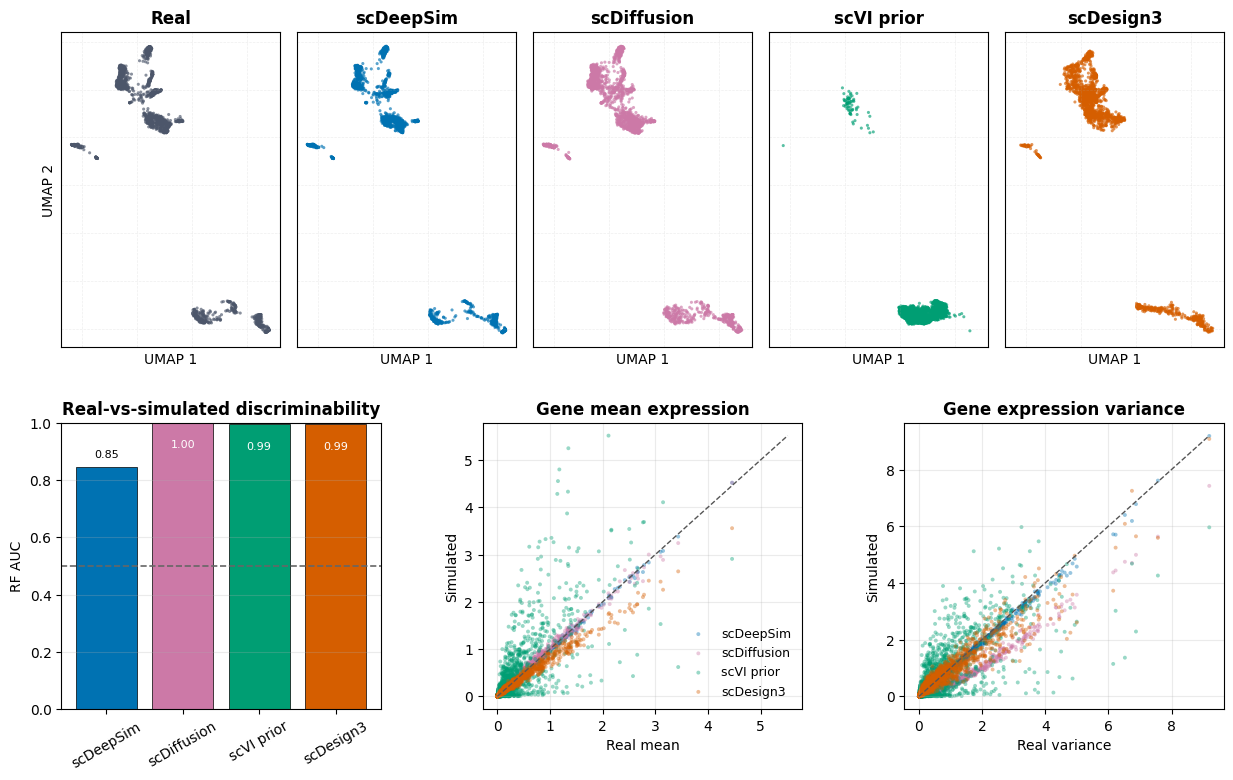

immune: learned_distribution


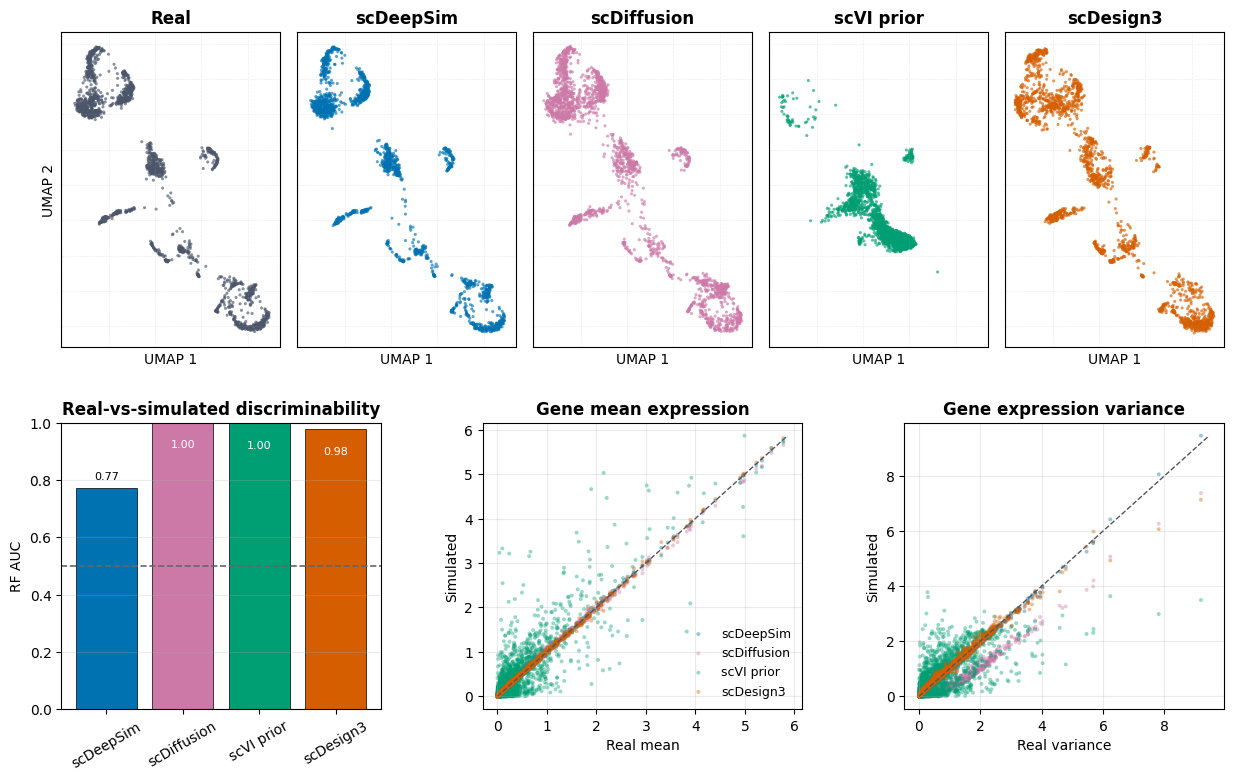

lung: reconstruction


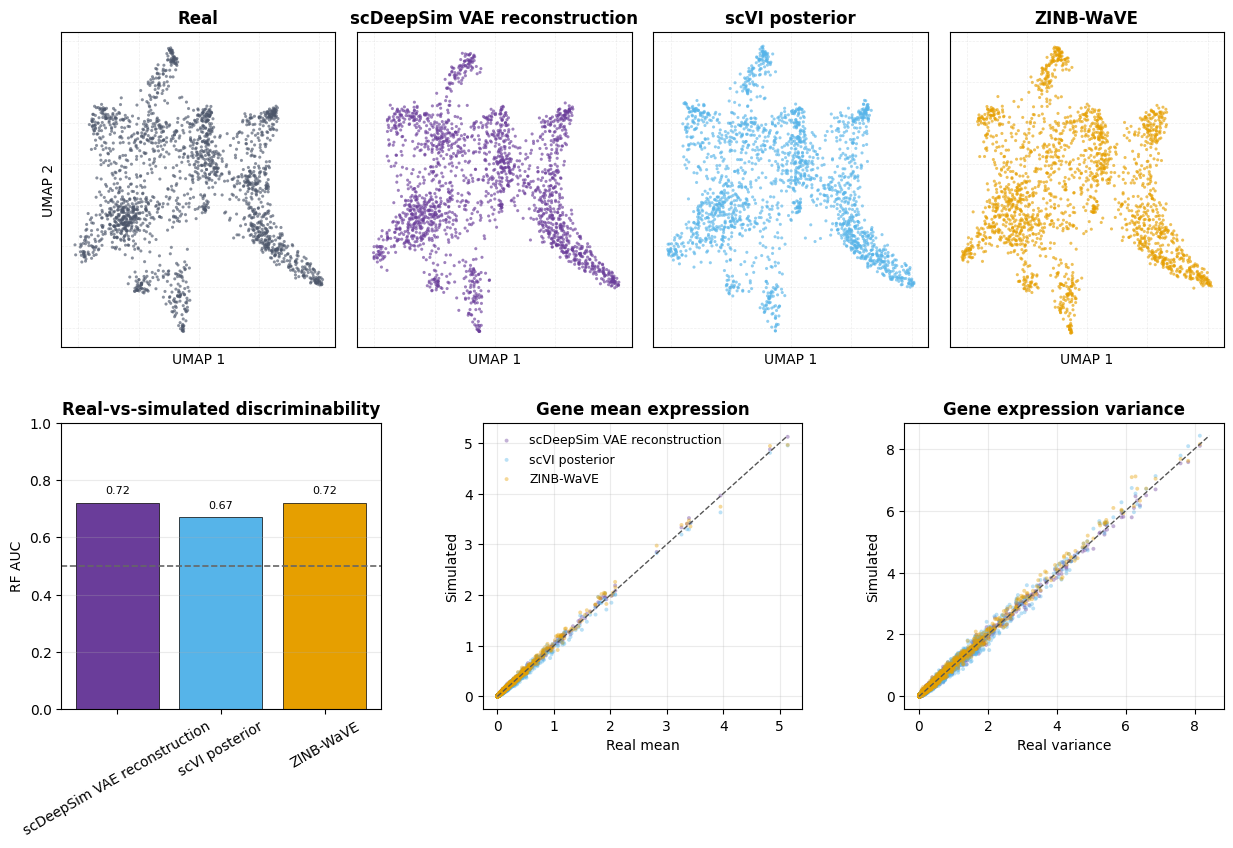

pancreas: reconstruction


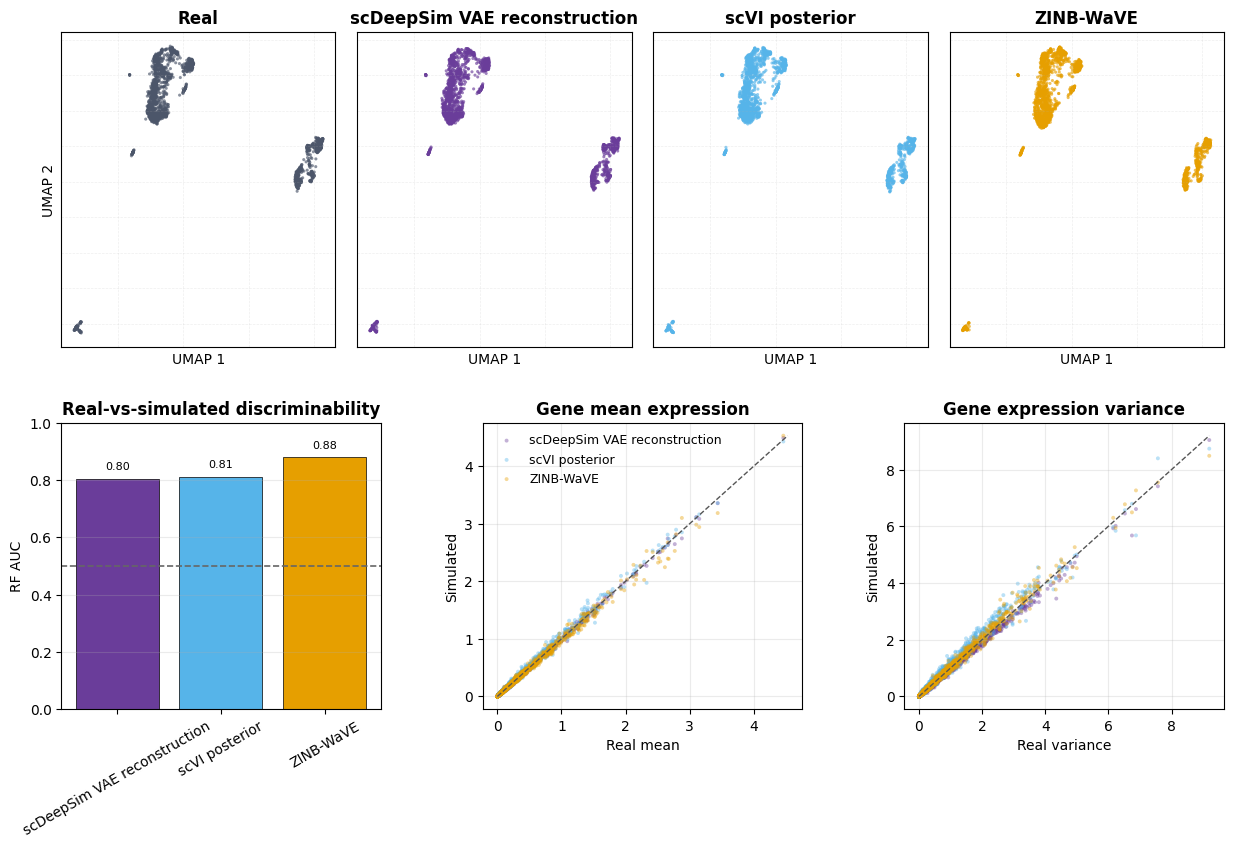

immune: reconstruction


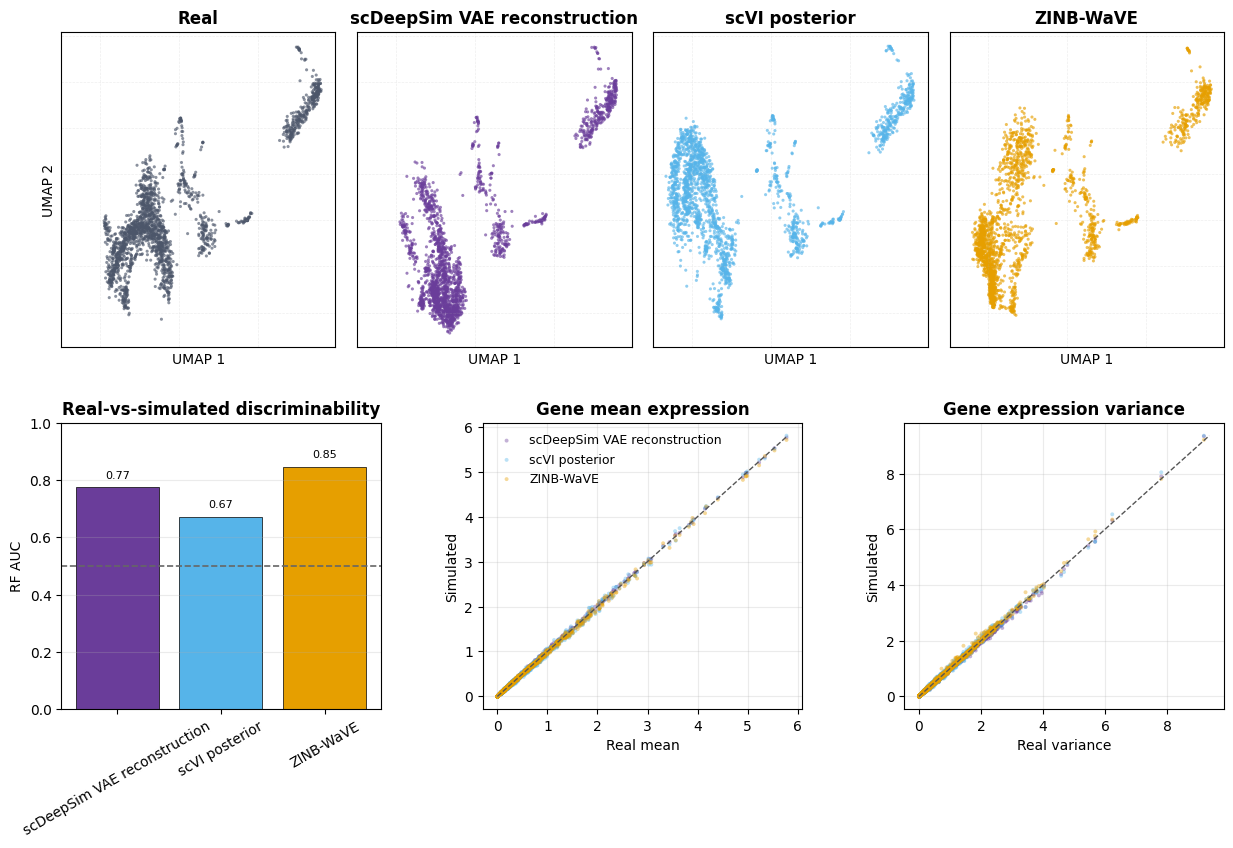

In [6]:
plt.close("all")
figures = {}
for case in CASES:
    figures[case] = plot_fidelity(results[case])
    print(f"{case[0]}: {case[1]}")
    plt.show()


## Save appendix figures

In [7]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for (dataset, category), fig in figures.items():
    output = OUTPUT_DIR / f"simulation_fidelity_{dataset}_{category}.png"
    fig.savefig(output, dpi=results[(dataset, category)]["dpi"], bbox_inches="tight")
    print(output)


/Users/malangtian/Documents/Research_Projects/scDiffusion_project/scDeepSim/paper/figures/results/simulation_fidelity_pancreas_learned_distribution.png
/Users/malangtian/Documents/Research_Projects/scDiffusion_project/scDeepSim/paper/figures/results/simulation_fidelity_immune_learned_distribution.png
/Users/malangtian/Documents/Research_Projects/scDiffusion_project/scDeepSim/paper/figures/results/simulation_fidelity_lung_reconstruction.png
/Users/malangtian/Documents/Research_Projects/scDiffusion_project/scDeepSim/paper/figures/results/simulation_fidelity_pancreas_reconstruction.png
/Users/malangtian/Documents/Research_Projects/scDiffusion_project/scDeepSim/paper/figures/results/simulation_fidelity_immune_reconstruction.png
